The model is

$$
\hat{y} = X\beta
$$

where:

- $X$ is the feature matrix
- $\beta$ is the parameter vector
- $\hat{y}$ is the prediction

The implementation uses mean squared error:

$$
J(\beta)=\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)^2
$$

with gradient:

$$
\nabla J(\beta)
=
\frac{2}{n}X^T(X\beta-y)
$$

and gradient-descent update:

$$
\beta
\leftarrow
\beta-\alpha\nabla J(\beta)
$$

where $\alpha$ is the learning rate.

The intercept is implemented by adding a column of ones to $X$.

In [1]:
import numpy as np

class LinearRegressionGD:

    def __init__(self, learning_rate=0.01, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.loss_history = []

    def fit(self, X, y):

        X = np.column_stack([
            np.ones(X.shape[0]),
            X
        ])

        n, p = X.shape

        self.beta = np.zeros(p)

        for epoch in range(self.epochs):

            # 1. Predictions
            predictions = X @ self.beta

            # 2. Errors
            errors = predictions - y

            # 3. Cost
            cost = np.mean(errors ** 2)

            # 4. Store cost
            self.loss_history.append(cost)

            # 5. Gradient
            gradient = (2 / n) * X.T @ errors

            # 6. Update parameters
            self.beta -= self.learning_rate * gradient

        return self

    def predict(self, X):

        X = np.column_stack([
            np.ones(X.shape[0]),
            X
        ])

        return X @ self.beta


In [2]:
import pandas as pd

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print(train.shape)
print(test.shape)

print(train.head())
print(train.info())

(1460, 81)
(1459, 80)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  

In [3]:
train["SalePrice"].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


In [4]:
train.isnull().sum().sort_values(ascending=False)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


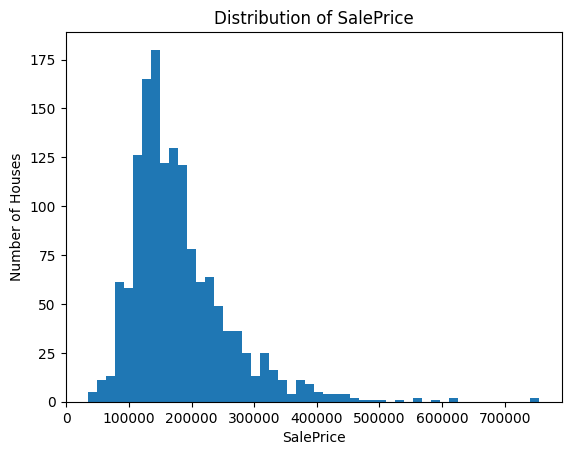

In [5]:
import matplotlib.pyplot as plt

plt.hist(train["SalePrice"], bins=50)
plt.xlabel("SalePrice")
plt.ylabel("Number of Houses")
plt.title("Distribution of SalePrice")
plt.show()

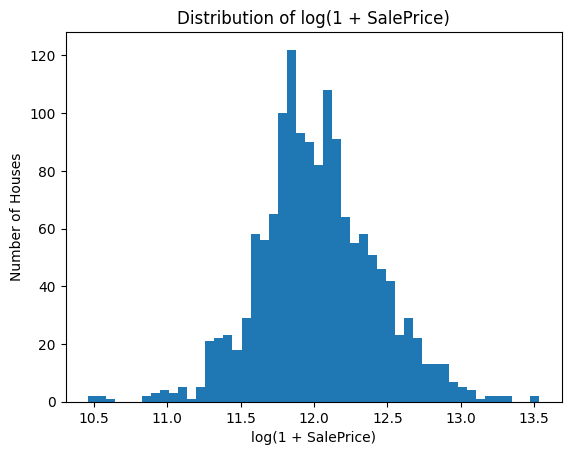

In [6]:
plt.hist(np.log1p(train["SalePrice"]), bins=50)
plt.xlabel("log(1 + SalePrice)")
plt.ylabel("Number of Houses")
plt.title("Distribution of log(1 + SalePrice)")
plt.show()

In [7]:
train.dtypes.value_counts()

,count
object,43
int64,35
float64,3


In [8]:
train.select_dtypes(include=["object"]).columns.tolist()

['MSZoning',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'PoolQC',
 'Fence',
 'MiscFeature',
 'SaleType',
 'SaleCondition']

In [9]:
train.select_dtypes(exclude=["object"]).columns.tolist()

['Id',
 'MSSubClass',
 'LotFrontage',
 'LotArea',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageYrBlt',
 'GarageCars',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'PoolArea',
 'MiscVal',
 'MoSold',
 'YrSold',
 'SalePrice']

In [10]:
X = train.drop("SalePrice", axis=1)
y = train["SalePrice"]

In [11]:
test_ids = test["Id"]

In [12]:
X = X.drop("Id", axis=1)

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [14]:
numeric_cols = X.select_dtypes(exclude=["object"]).columns
categorical_cols = X.select_dtypes(include=["object"]).columns

print("Numerical:", len(numeric_cols))
print("Categorical:", len(categorical_cols))

Numerical: 36
Categorical: 43


In [15]:
print("Numerical missing values:")
print(X[numeric_cols].isnull().sum().sort_values(ascending=False).head(20))

Numerical missing values:
LotFrontage     259
GarageYrBlt      81
MasVnrArea        8
MSSubClass        0
OverallQual       0
LotArea           0
YearBuilt         0
OverallCond       0
BsmtFinSF1        0
BsmtFinSF2        0
BsmtUnfSF         0
YearRemodAdd      0
1stFlrSF          0
2ndFlrSF          0
LowQualFinSF      0
GrLivArea         0
BsmtFullBath      0
BsmtHalfBath      0
FullBath          0
TotalBsmtSF       0
dtype: int64


In [16]:
print("Categorical missing values:")
print(X[categorical_cols].isnull().sum().sort_values(ascending=False).head(20))

Categorical missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
GarageFinish      81
GarageQual        81
GarageType        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtQual          37
BsmtCond          37
Electrical         1
Condition1         0
Condition2         0
LotShape           0
Street             0
dtype: int64


In [17]:
median_lot_frontage = X_train["LotFrontage"].median()

X_train["LotFrontage"] = X_train["LotFrontage"].fillna(
    median_lot_frontage
)

X_val["LotFrontage"] = X_val["LotFrontage"].fillna(
    median_lot_frontage
)

In [18]:
X_train["GarageYrBlt"] = X_train["GarageYrBlt"].fillna(
    0
)

X_val["GarageYrBlt"] = X_val["GarageYrBlt"].fillna(
    0
)

In [19]:
X_train["Electrical"].mode()[0]

'SBrkr'

In [20]:
X_train["Electrical"] = X_train["Electrical"].fillna(
    X_train["Electrical"].mode()[0]
)

In [21]:
print(train.loc[train["GarageType"].isna(),
                ["GarageType", "GarageYrBlt", "GarageFinish",
                 "GarageCars", "GarageArea", "GarageQual",
                 "GarageCond"]].head(10))

    GarageType  GarageYrBlt GarageFinish  GarageCars  GarageArea GarageQual  \
39         NaN          NaN          NaN           0           0        NaN   
48         NaN          NaN          NaN           0           0        NaN   
78         NaN          NaN          NaN           0           0        NaN   
88         NaN          NaN          NaN           0           0        NaN   
89         NaN          NaN          NaN           0           0        NaN   
99         NaN          NaN          NaN           0           0        NaN   
108        NaN          NaN          NaN           0           0        NaN   
125        NaN          NaN          NaN           0           0        NaN   
127        NaN          NaN          NaN           0           0        NaN   
140        NaN          NaN          NaN           0           0        NaN   

    GarageCond  
39         NaN  
48         NaN  
78         NaN  
88         NaN  
89         NaN  
99         NaN  
108        

In [22]:
print(train.loc[train["MasVnrArea"].isna(),
                ["MasVnrArea", "MasVnrType"]])

      MasVnrArea MasVnrType
234          NaN        NaN
529          NaN        NaN
650          NaN        NaN
936          NaN        NaN
973          NaN        NaN
977          NaN        NaN
1243         NaN        NaN
1278         NaN        NaN


In [23]:
print(train.loc[train["Electrical"].isna(),
                ["Electrical", "OverallQual", "GrLivArea", "SalePrice"]])

     Electrical  OverallQual  GrLivArea  SalePrice
1379        NaN            5       1394     167500


In [24]:
garage_cat_cols = [
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond"
]

X[garage_cat_cols] = X[garage_cat_cols].fillna("None")

In [25]:
print(X.loc[
    X["GarageType"] == "None",
    ["GarageType", "GarageYrBlt", "GarageFinish",
     "GarageCars", "GarageArea", "GarageQual",
     "GarageCond"]
].head(10))

    GarageType  GarageYrBlt GarageFinish  GarageCars  GarageArea GarageQual  \
39        None          NaN         None           0           0       None   
48        None          NaN         None           0           0       None   
78        None          NaN         None           0           0       None   
88        None          NaN         None           0           0       None   
89        None          NaN         None           0           0       None   
99        None          NaN         None           0           0       None   
108       None          NaN         None           0           0       None   
125       None          NaN         None           0           0       None   
127       None          NaN         None           0           0       None   
140       None          NaN         None           0           0       None   

    GarageCond  
39        None  
48        None  
78        None  
88        None  
89        None  
99        None  
108       N

In [26]:
basement_cat_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

X[basement_cat_cols] = X[basement_cat_cols].fillna("None")

In [27]:
print(X.loc[
    X["BsmtQual"] == "None",
    ["BsmtQual", "BsmtCond", "BsmtExposure",
     "BsmtFinType1", "BsmtFinType2"]
].head(10))

    BsmtQual BsmtCond BsmtExposure BsmtFinType1 BsmtFinType2
17      None     None         None         None         None
39      None     None         None         None         None
90      None     None         None         None         None
102     None     None         None         None         None
156     None     None         None         None         None
182     None     None         None         None         None
259     None     None         None         None         None
342     None     None         None         None         None
362     None     None         None         None         None
371     None     None         None         None         None


In [28]:
print(X.loc[
    X["BsmtQual"] == "None",
    ["BsmtQual", "BsmtFinSF1", "BsmtFinSF2",
     "BsmtUnfSF", "TotalBsmtSF",
     "BsmtFullBath", "BsmtHalfBath"]
].head(10))

    BsmtQual  BsmtFinSF1  BsmtFinSF2  BsmtUnfSF  TotalBsmtSF  BsmtFullBath  \
17      None           0           0          0            0             0   
39      None           0           0          0            0             0   
90      None           0           0          0            0             0   
102     None           0           0          0            0             0   
156     None           0           0          0            0             0   
182     None           0           0          0            0             0   
259     None           0           0          0            0             0   
342     None           0           0          0            0             0   
362     None           0           0          0            0             0   
371     None           0           0          0            0             0   

     BsmtHalfBath  
17              0  
39              0  
90              0  
102             0  
156             0  
182             0  
2

In [29]:
basement_num_cols = [
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath"
]

X[basement_num_cols] = X[basement_num_cols].fillna(0)

In [30]:
print(X[basement_cat_cols + basement_num_cols].isna().sum())

BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
BsmtFinSF1      0
BsmtFinSF2      0
BsmtUnfSF       0
TotalBsmtSF     0
BsmtFullBath    0
BsmtHalfBath    0
dtype: int64


In [31]:
X["MasVnrType"] = X["MasVnrType"].fillna("None")

In [32]:
X["MasVnrArea"] = X["MasVnrArea"].fillna(0)

In [33]:
print(X.loc[
    X["MasVnrType"] == "None",
    ["MasVnrType", "MasVnrArea"]
].head(10))

   MasVnrType  MasVnrArea
1        None         0.0
3        None         0.0
5        None         0.0
8        None         0.0
9        None         0.0
10       None         0.0
12       None         0.0
15       None         0.0
17       None         0.0
18       None         0.0


In [34]:
absence_cat_cols = [
    "FireplaceQu",
    "PoolQC",
    "Alley",
    "Fence",
    "MiscFeature"
]

X[absence_cat_cols] = X[absence_cat_cols].fillna("None")

In [35]:
print(X[absence_cat_cols].isna().sum())

FireplaceQu    0
PoolQC         0
Alley          0
Fence          0
MiscFeature    0
dtype: int64


In [36]:
X["Electrical"].value_counts()

,count
Electrical,
SBrkr,1334
FuseA,94
FuseF,27
FuseP,3
Mix,1


In [37]:
electrical_mode = X_train["Electrical"].mode()[0]

X_train["Electrical"] = X_train["Electrical"].fillna(electrical_mode)
X_val["Electrical"] = X_val["Electrical"].fillna(electrical_mode)

In [38]:
print("Training missing values:")
print(X_train.isna().sum().sort_values(ascending=False).head(20))

Training missing values:
PoolQC          1162
MiscFeature     1122
Alley           1094
Fence            935
MasVnrType       683
FireplaceQu      547
GarageType        64
GarageCond        64
GarageFinish      64
GarageQual        64
BsmtFinType2      28
BsmtExposure      28
BsmtQual          28
BsmtCond          28
BsmtFinType1      28
MasVnrArea         6
Condition2         0
BldgType           0
Neighborhood       0
LandSlope          0
dtype: int64


In [39]:
print("\nValidation missing values:")
print(X_val.isna().sum().sort_values(ascending=False).head(20))


Validation missing values:
PoolQC          291
MiscFeature     284
Alley           275
Fence           244
MasVnrType      189
FireplaceQu     143
GarageType       17
GarageCond       17
GarageFinish     17
GarageQual       17
BsmtExposure     10
BsmtFinType2     10
BsmtCond          9
BsmtFinType1      9
BsmtQual          9
MasVnrArea        2
Condition2        0
BldgType          0
Neighborhood      0
LandSlope         0
dtype: int64


In [40]:
absence_cat_cols = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "MasVnrType"
]

for col in absence_cat_cols:
    X_train[col] = X_train[col].fillna("None")
    X_val[col] = X_val[col].fillna("None")

In [41]:
absence_num_cols = [
    "GarageYrBlt",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath"
]

for col in absence_num_cols:
    X_train[col] = X_train[col].fillna(0)
    X_val[col] = X_val[col].fillna(0)

In [42]:
print("Training missing values:")
print(X_train.isna().sum().sort_values(ascending=False).head(20))

Training missing values:
MSSubClass      0
MSZoning        0
LotFrontage     0
LotArea         0
Street          0
Alley           0
LotShape        0
LandContour     0
Utilities       0
LotConfig       0
LandSlope       0
Neighborhood    0
Condition1      0
Condition2      0
BldgType        0
HouseStyle      0
OverallQual     0
OverallCond     0
YearBuilt       0
YearRemodAdd    0
dtype: int64


In [43]:
print("\nValidation missing values:")
print(X_val.isna().sum().sort_values(ascending=False).head(20))


Validation missing values:
MSSubClass      0
MSZoning        0
LotFrontage     0
LotArea         0
Street          0
Alley           0
LotShape        0
LandContour     0
Utilities       0
LotConfig       0
LandSlope       0
Neighborhood    0
Condition1      0
Condition2      0
BldgType        0
HouseStyle      0
OverallQual     0
OverallCond     0
YearBuilt       0
YearRemodAdd    0
dtype: int64


In [44]:
print("Training total missing:", X_train.isna().sum().sum())
print("Validation total missing:", X_val.isna().sum().sum())

Training total missing: 0
Validation total missing: 0


In [45]:
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()

print(categorical_cols)
print("Number of categorical columns:", len(categorical_cols))

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']
Number of categorical columns: 43


In [46]:
print(X_train["MSZoning"].value_counts())

MSZoning
RL         924
RM         172
FV          53
RH          15
C (all)      4
Name: count, dtype: int64


In [47]:
X_train["MSZoning_RM"] = (X_train["MSZoning"] == "RM").astype(int)
X_train["MSZoning_FV"] = (X_train["MSZoning"] == "FV").astype(int)
X_train["MSZoning_RH"] = (X_train["MSZoning"] == "RH").astype(int)
X_train["MSZoning_C"] = (X_train["MSZoning"] == "C (all)").astype(int)

In [48]:
X_val["MSZoning_RM"] = (X_val["MSZoning"] == "RM").astype(int)
X_val["MSZoning_FV"] = (X_val["MSZoning"] == "FV").astype(int)
X_val["MSZoning_RH"] = (X_val["MSZoning"] == "RH").astype(int)
X_val["MSZoning_C"] = (X_val["MSZoning"] == "C (all)").astype(int)

In [49]:
print(
    X_train[
        ["MSZoning", "MSZoning_RM", "MSZoning_FV",
         "MSZoning_RH", "MSZoning_C"]
    ].head(10)
)

     MSZoning  MSZoning_RM  MSZoning_FV  MSZoning_RH  MSZoning_C
254        RL            0            0            0           0
1066       RL            0            0            0           0
638        RL            0            0            0           0
799        RL            0            0            0           0
380        RL            0            0            0           0
303        RL            0            0            0           0
86         RL            0            0            0           0
1385       RM            1            0            0           0
265        RL            0            0            0           0
793        RL            0            0            0           0


One-hot encoding

In [50]:
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

train_encoded = {}
val_encoded = {}

for col in categorical_cols:

    # Categories come ONLY from training data
    categories = X_train[col].unique()

    # Most frequent category = baseline
    baseline = X_train[col].value_counts().idxmax()

    for category in categories:

        if category == baseline:
            continue

        column_name = col + "_" + str(category)

        train_encoded[column_name] = (
            X_train[col] == category
        ).astype(int)

        val_encoded[column_name] = (
            X_val[col] == category
        ).astype(int)

In [51]:
train_encoded = pd.DataFrame(
    train_encoded,
    index=X_train.index
)

val_encoded = pd.DataFrame(
    val_encoded,
    index=X_val.index
)

In [52]:
numeric_cols = X_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

In [53]:
X_train_final = pd.concat(
    [
        X_train[numeric_cols],
        train_encoded
    ],
    axis=1
)

X_val_final = pd.concat(
    [
        X_val[numeric_cols],
        val_encoded
    ],
    axis=1
)

In [54]:
print(X_train_final.shape)
print(X_val_final.shape)

(1168, 261)
(292, 261)


In [55]:
print(
    X_train_final.columns.equals(
        X_val_final.columns
    )
)

True


In [56]:
print(X_train_final.dtypes.value_counts())

int64      258
float64      3
Name: count, dtype: int64


In [57]:
train_mean = X_train_final.mean()
train_std = X_train_final.std()

## Feature scaling

Numerical and encoded features are standardized using training-set statistics:

$$
z=\frac{x-\mu_{\text{train}}}{\sigma_{\text{train}}}
$$

The same training means and standard deviations are applied to validation/test data.

Scaling is important here because gradient descent is sensitive to feature magnitudes.


In [58]:
X_train_scaled = (
    X_train_final - train_mean
) / train_std

In [59]:
X_val_scaled = (
    X_val_final - train_mean
) / train_std

In [60]:
print(X_train_scaled.mean().head())

MSSubClass     6.387585e-17
LotFrontage   -1.946692e-16
LotArea        1.672939e-17
OverallQual   -6.995926e-17
OverallCond   -2.129195e-16
dtype: float64


In [61]:
zero_variance_cols = X_train_scaled.columns[
    X_train_scaled.std() == 0
]

print(zero_variance_cols)
print("Number:", len(zero_variance_cols))

Index([], dtype='object')
Number: 0


In [62]:
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)

In [63]:
print(y_train.head())
print(y_train_log.head())

254     145000
1066    178000
638      85000
799     175000
380     127000
Name: SalePrice, dtype: int64
254     11.884496
1066    12.089544
638     11.350418
799     12.072547
380     11.751950
Name: SalePrice, dtype: float64


In [64]:
X_train_np = X_train_scaled.to_numpy()
X_val_np = X_val_scaled.to_numpy()

y_train_np = y_train_log.to_numpy()
y_val_np = y_val_log.to_numpy()

In [65]:
print("X_train:", X_train_np.shape)
print("y_train:", y_train_np.shape)

print("X_val:", X_val_np.shape)
print("y_val:", y_val_np.shape)

X_train: (1168, 261)
y_train: (1168,)
X_val: (292, 261)
y_val: (292,)


In [66]:
model = LinearRegressionGD(
    learning_rate=0.01,
    epochs=5000
)

model.fit(
    X_train_np,
    y_train_np
)

In [67]:
y_pred_log = model.predict(X_val_np)

In [68]:
print(y_pred_log[:10])
print(y_val_log[:10])

[11.94121576 12.74630087 11.50970683 12.01140481 12.64856521 11.27798399
 12.41549815 11.89974565 11.22475417 11.87031242]
892     11.947956
1105    12.691584
413     11.652696
522     11.976666
1036    12.661917
614     11.231901
218     12.649158
1160    11.891369
649     11.344519
887     11.816734
Name: SalePrice, dtype: float64


In [69]:
rmsle = np.sqrt(
    np.mean(
        (y_pred_log - y_val_log) ** 2
    )
)

print("Validation RMSLE:", rmsle)

Validation RMSLE: 0.12506356875738142


In [70]:
rmse_log = np.sqrt(
    np.mean(
        (y_pred_log - y_val_log) ** 2
    )
)

print("Log RMSE:", rmse_log)

Log RMSE: 0.12506356875738142


In [71]:
y_pred = np.expm1(y_pred_log)

In [72]:
print(y_pred[:10])
print(y_val[:10].to_numpy())

[153462.15057497 343278.70730295  99677.65391986 164620.60364412
 311315.4547323   79060.71180443 246592.90464741 147228.17225734
  74962.3176494  142957.89468871]
[154500 325000 115000 159000 315500  75500 311500 146000  84500 135500]


In [73]:
rmsle = np.sqrt(
    np.mean(
        (y_pred_log - y_val_log) ** 2
    )
)

print("Validation RMSLE:", rmsle)

Validation RMSLE: 0.12506356875738142


In [74]:
rmse = np.sqrt(
    np.mean(
        (y_pred - y_val.to_numpy()) ** 2
    )
)

print("Validation RMSE: $", rmse)

Validation RMSE: $ 22143.736301666027


In [75]:
print("Initial loss:", model.loss_history[0])
print("Final loss:", model.loss_history[-1])

Initial loss: 144.8891818308348
Final loss: 0.008416388827907406


In [76]:
print("Last 10 losses:")

for loss in model.loss_history[-10:]:
    print(loss)

Last 10 losses:
0.008416394412963928
0.008416393790912868
0.008416393169234983
0.008416392547929854
0.008416391926997118
0.008416391306436472
0.008416390686247522
0.008416390066429937
0.008416389446983351
0.008416388827907406


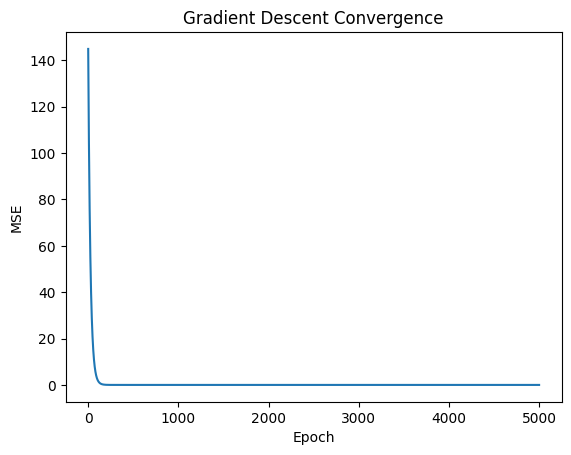

In [77]:
import matplotlib.pyplot as plt

plt.plot(model.loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Gradient Descent Convergence")

plt.show()

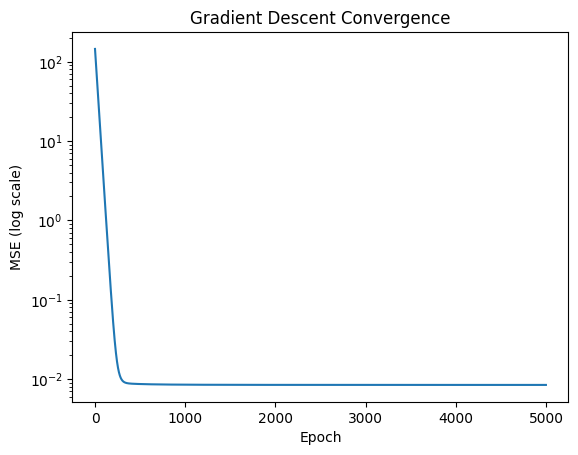

In [78]:
plt.plot(model.loss_history)

plt.yscale("log")

plt.xlabel("Epoch")
plt.ylabel("MSE (log scale)")
plt.title("Gradient Descent Convergence")

plt.show()

In [79]:
y_train_pred_log = model.predict(X_train_np)
y_val_pred_log = model.predict(X_val_np)

In [80]:
train_rmsle = np.sqrt(
    np.mean((y_train_pred_log - y_train_np) ** 2)
)

val_rmsle = np.sqrt(
    np.mean((y_val_pred_log - y_val_np) ** 2)
)

print("Training RMSLE:", train_rmsle)
print("Validation RMSLE:", val_rmsle)

Training RMSLE: 0.09174087534573537
Validation RMSLE: 0.12506356875738142


In [81]:
y_val_pred = np.expm1(y_val_pred_log)
y_val_actual = np.expm1(y_val_np)

In [82]:
errors = y_val_pred - y_val_actual

In [83]:
error_df = pd.DataFrame({
    "Actual": y_val_actual,
    "Predicted": y_val_pred,
    "Error": errors,
    "AbsoluteError": np.abs(errors)
}, index=y_val.index)

In [84]:
error_df.sort_values(
    "AbsoluteError",
    ascending=False
).head(10)

,Actual,Predicted,Error,AbsoluteError
581,253293.0,370173.382118,116880.382118,116880.382118
898,611657.0,503154.426846,-108502.573154,108502.573154
774,395000.0,302653.548123,-92346.451877,92346.451877
588,143000.0,218546.611332,75546.611332,75546.611332
529,200624.0,271612.880665,70988.880665,70988.880665
218,311500.0,246592.904647,-64907.095353,64907.095353
1046,556581.0,498998.425661,-57582.574339,57582.574339
58,438780.0,495014.327857,56234.327857,56234.327857
261,276000.0,329994.137236,53994.137236,53994.137236
184,127000.0,180578.717451,53578.717451,53578.717451


In [85]:
log_errors = y_val_pred_log - y_val_np

In [86]:
error_log_df = pd.DataFrame({
    "Actual": y_val_actual,
    "Predicted": y_val_pred,
    "Error": errors,
    "AbsoluteError": np.abs(log_errors)
}, index=y_val.index)

In [87]:
error_log_df["LogError"] = log_errors
error_log_df["AbsoluteLogError"] = np.abs(log_errors)

In [88]:
error_log_df.sort_values(
    "AbsoluteLogError",
    ascending=False
).head(10)

,Actual,Predicted,Error,AbsoluteError,LogError,AbsoluteLogError
30,40000.0,65085.150303,25085.150303,0.486807,0.486807,0.486807
589,79500.0,124889.614443,45389.614443,0.451669,0.451669,0.451669
1432,64500.0,101172.053431,36672.053431,0.450152,0.450152,0.450152
588,143000.0,218546.611332,75546.611332,0.424152,0.424152,0.424152
479,89471.0,135483.808179,46012.808179,0.414934,0.414934,0.414934
581,253293.0,370173.382118,116880.382118,0.379423,0.379423,0.379423
874,66500.0,96258.591944,29758.591944,0.369832,0.369832,0.369832
184,127000.0,180578.717451,53578.717451,0.351977,0.351977,0.351977
1131,93500.0,129515.872987,36015.872987,0.325839,0.325839,0.325839
529,200624.0,271612.880665,70988.880665,0.302944,0.302944,0.302944


In [89]:
learning_rates = [0.001, 0.003, 0.01, 0.03, 0.1]

In [90]:
results_lr = []

for lr in learning_rates:

    model_test = LinearRegressionGD(
        learning_rate=lr,
        epochs=5000
    )

    model_test.fit(
        X_train_np,
        y_train_np
    )

    train_pred = model_test.predict(X_train_np)
    val_pred = model_test.predict(X_val_np)

    train_rmsle = np.sqrt(
        np.mean((train_pred - y_train_np) ** 2)
    )

    val_rmsle = np.sqrt(
        np.mean((val_pred - y_val_np) ** 2)
    )

    results_lr.append({
        "Learning Rate": lr,
        "Train RMSLE": train_rmsle,
        "Validation RMSLE": val_rmsle,
        "Final Loss": model_test.loss_history[-1]
    })

results_lr

/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:136: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_5854/1412314399.py:30: RuntimeWarning: overflow encountered in square
  cost = np.mean(errors ** 2)
/tmp/ipykernel_5854/1412314399.py:24: RuntimeWarning: overflow encountered in matmul
  predictions = X @ self.beta
/tmp/ipykernel_5854/1412314399.py:36: RuntimeWarning: invalid value encountered in matmul
  gradient = (2 / n) * X.T @ errors
/tmp/ipykernel_5854/1412314399.py:24: RuntimeWarning: invalid value encountered in matmul
  predictions = X @ self.beta


[{'Learning Rate': 0.001,
  'Train RMSLE': np.float64(0.09292634094284892),
  'Validation RMSLE': np.float64(0.12652512629178267),
  'Final Loss': np.float64(0.008635374986371847)},
 {'Learning Rate': 0.003,
  'Train RMSLE': np.float64(0.09186186636961467),
  'Validation RMSLE': np.float64(0.1250882054491687),
  'Final Loss': np.float64(0.008438614058755033)},
 {'Learning Rate': 0.01,
  'Train RMSLE': np.float64(0.09174087534573537),
  'Validation RMSLE': np.float64(0.12506356875738142),
  'Final Loss': np.float64(0.008416388827907406)},
 {'Learning Rate': 0.03,
  'Train RMSLE': np.float64(0.09172921888532443),
  'Validation RMSLE': np.float64(0.12490533718550151),
  'Final Loss': np.float64(0.008414249977225032)},
 {'Learning Rate': 0.1,
  'Train RMSLE': np.float64(nan),
  'Validation RMSLE': np.float64(nan),
  'Final Loss': np.float64(nan)}]

In [91]:
pd.DataFrame(results_lr)

,Learning Rate,Train RMSLE,Validation RMSLE,Final Loss
0,0.001,0.092926,0.126525,0.008635
1,0.003,0.091862,0.125088,0.008439
2,0.010,0.091741,0.125064,0.008416
3,0.030,0.091729,0.124905,0.008414
4,0.100,NaN,NaN,NaN


In [92]:
learning_rates = [0.001, 0.01, 0.03]

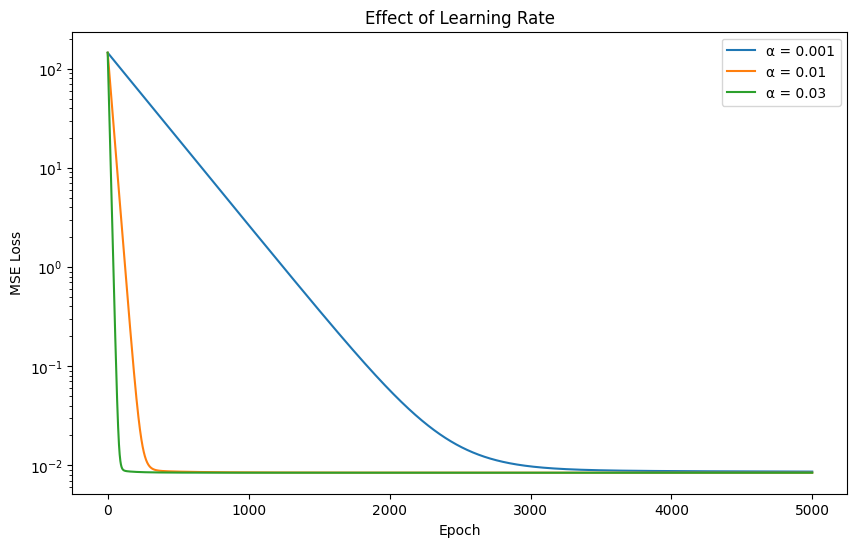

In [93]:
plt.figure(figsize=(10, 6))

for lr in learning_rates:

    model_test = LinearRegressionGD(
        learning_rate=lr,
        epochs=5000
    )

    model_test.fit(
        X_train_np,
        y_train_np
    )

    plt.plot(
        model_test.loss_history,
        label=f"α = {lr}"
    )

plt.yscale("log")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Effect of Learning Rate")
plt.legend()

plt.show()

In [94]:
epochs_list = [
    100,
    500,
    1000,
    2000,
    5000,
    10000
]

In [95]:
results_epochs = []

for epochs in epochs_list:

    model_test = LinearRegressionGD(
        learning_rate=0.01,
        epochs=epochs
    )

    model_test.fit(
        X_train_np,
        y_train_np
    )

    train_pred = model_test.predict(X_train_np)
    val_pred = model_test.predict(X_val_np)

    train_rmsle = np.sqrt(
        np.mean((train_pred - y_train_np) ** 2)
    )

    val_rmsle = np.sqrt(
        np.mean((val_pred - y_val_np) ** 2)
    )

    results_epochs.append({
        "Epochs": epochs,
        "Train RMSLE": train_rmsle,
        "Validation RMSLE": val_rmsle,
        "Final Loss": model_test.loss_history[-1]
    })

pd.DataFrame(results_epochs)

,Epochs,Train RMSLE,Validation RMSLE,Final Loss
0,100,1.598635,1.595929,2.660613
1,500,0.092924,0.126527,0.008636
2,1000,0.092063,0.125295,0.008476
3,2000,0.091796,0.125078,0.008427
4,5000,0.091741,0.125064,0.008416
5,10000,0.091733,0.124963,0.008415


In [96]:
# Full training data
X_full = train.drop(columns=["SalePrice", "Id"]).copy()
y_full = np.log1p(train["SalePrice"])

# Kaggle test data
X_test = test.drop(columns=["Id"]).copy()

# Keep IDs for submission
test_ids = test["Id"].copy()

print("X_full:", X_full.shape)
print("X_test:", X_test.shape)

X_full: (1460, 79)
X_test: (1459, 79)


In [97]:
absence_cat_cols = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "MasVnrType"
]

for col in absence_cat_cols:
    X_full[col] = X_full[col].fillna("None")
    X_test[col] = X_test[col].fillna("None")

In [98]:
absence_num_cols = [
    "GarageYrBlt",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath"
]

for col in absence_num_cols:
    X_full[col] = X_full[col].fillna(0)
    X_test[col] = X_test[col].fillna(0)

In [99]:
print("Training missing:")
print(X_full.isna().sum().sort_values(ascending=False).head(20))

print("\nTest missing:")
print(X_test.isna().sum().sort_values(ascending=False).head(20))

Training missing:
LotFrontage     259
Electrical        1
MSSubClass        0
LotArea           0
Street            0
Alley             0
MSZoning          0
LandContour       0
Utilities         0
LotConfig         0
LandSlope         0
Neighborhood      0
Condition1        0
Condition2        0
LotShape          0
BldgType          0
HouseStyle        0
OverallCond       0
OverallQual       0
YearRemodAdd      0
dtype: int64

Test missing:
LotFrontage     227
MSZoning          4
Utilities         2
Functional        2
Exterior2nd       1
Exterior1st       1
KitchenQual       1
GarageCars        1
SaleType          1
GarageArea        1
LotShape          0
LotArea           0
Street            0
Alley             0
MSSubClass        0
BldgType          0
Condition2        0
Condition1        0
Neighborhood      0
LandSlope         0
dtype: int64


In [100]:
categorical_cols = X_full.select_dtypes(
    include=["object"]
).columns.tolist()

for col in categorical_cols:

    mode_value = X_full[col].mode()[0]

    X_full[col] = X_full[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)

In [101]:
numeric_cols = X_full.select_dtypes(
    exclude=["object"]
).columns.tolist()

for col in numeric_cols:

    median_value = X_full[col].median()

    X_full[col] = X_full[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

In [102]:
print("Training missing:", X_full.isna().sum().sum())
print("Test missing:", X_test.isna().sum().sum())

Training missing: 0
Test missing: 0


In [103]:
train_encoded = {}
test_encoded = {}

for col in categorical_cols:

    # Categories learned from training data
    categories = X_full[col].unique()

    # Most frequent category = baseline
    baseline = X_full[col].value_counts().idxmax()

    for category in categories:

        if category == baseline:
            continue

        column_name = col + "_" + str(category)

        train_encoded[column_name] = (
            X_full[col] == category
        ).astype(int)

        test_encoded[column_name] = (
            X_test[col] == category
        ).astype(int)

In [104]:
train_encoded = pd.DataFrame(
    train_encoded,
    index=X_full.index
)

test_encoded = pd.DataFrame(
    test_encoded,
    index=X_test.index
)

In [105]:
X_full_final = pd.concat(
    [
        X_full[numeric_cols],
        train_encoded
    ],
    axis=1
)

X_test_final = pd.concat(
    [
        X_test[numeric_cols],
        test_encoded
    ],
    axis=1
)

In [106]:
print(X_full_final.shape)
print(X_test_final.shape)

print(
    "Columns match:",
    X_full_final.columns.equals(
        X_test_final.columns
    )
)

(1460, 259)
(1459, 259)
Columns match: True


In [107]:
train_mean = X_full_final.mean()
train_std = X_full_final.std()

# Protect against zero standard deviation
train_std[train_std == 0] = 1

In [108]:
X_full_scaled = (
    X_full_final - train_mean
) / train_std

X_test_scaled = (
    X_test_final - train_mean
) / train_std

In [109]:
X_full_np = X_full_scaled.to_numpy()
X_test_np = X_test_scaled.to_numpy()

y_full_np = y_full.to_numpy()

print("X_full:", X_full_np.shape)
print("y_full:", y_full_np.shape)
print("X_test:", X_test_np.shape)

X_full: (1460, 259)
y_full: (1460,)
X_test: (1459, 259)


In [110]:
final_model = LinearRegressionGD(
    learning_rate=0.03,
    epochs=5000
)

final_model.fit(
    X_full_np,
    y_full_np
)

In [111]:
y_test_pred_log = final_model.predict(
    X_test_np
)

In [112]:
y_test_pred = np.expm1(
    y_test_pred_log
)

In [113]:
print(y_test_pred[:10])

[121191.26765431 166565.51268041 183046.49640413 203598.4547463
 193380.69807032 171679.70004811 178611.82367168 163201.15988592
 195532.18231293 120028.33942372]


In [114]:
submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": y_test_pred
})

In [115]:
submission.to_csv(
    "submission.csv",
    index=False
)

In [116]:
print("Submission shape:", submission.shape)
print(submission.head())
print(submission.isna().sum())

Submission shape: (1459, 2)
     Id      SalePrice
0  1461  121191.267654
1  1462  166565.512680
2  1463  183046.496404
3  1464  203598.454746
4  1465  193380.698070
Id           0
SalePrice    0
dtype: int64


In [117]:
assert len(submission) == len(test)

assert submission.columns.tolist() == [
    "Id",
    "SalePrice"
]

assert submission["Id"].equals(test_ids)

assert submission["SalePrice"].notna().all()

assert np.isfinite(
    submission["SalePrice"]
).all()

print("✅ Submission is ready!")

✅ Submission is ready!
